In [ ]:
# Step 1: Import Necessary Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning tools
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Configure visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("Libraries loaded successfully!")

Libraries loaded successfully!


In [ ]:
# Step 2: Read data file
file_path = 'marketing_campaign.csv'

try:
    df = pd.read_csv(file_path, sep='\t')
    print("Data loaded successfully!")
    print(f"Dataset shape: {df.shape[0]} rows and {df.shape[1]} columns.")
except FileNotFoundError:
    print("File not found. Please place 'marketing_campaign.csv' in the current working directory.")

# View first 5 rows
df.head()

Data loaded successfully!
Dataset shape: 2240 rows and 29 columns.


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [ ]:
# Step 3: Clean data and engineer RFM features

df = df.copy()

# Fill missing income for supplementary customer profiling
if 'Income' in df.columns:
    df['Income'] = df['Income'].fillna(df['Income'].median())

# Monetary: total spending across product categories
spending_cols = [
    'MntWines', 'MntFruits', 'MntMeatProducts',
    'MntFishProducts', 'MntSweetProducts', 'MntGoldProds'
]
df['Monetary'] = df[spending_cols].sum(axis=1)

# Frequency: sum of recorded purchases across available channels
purchase_cols = [
    'NumWebPurchases', 'NumCatalogPurchases',
    'NumStorePurchases', 'NumDealsPurchases'
]
df['Frequency'] = df[purchase_cols].sum(axis=1)

# Recency is already supplied as days since last purchase
df['Recency'] = pd.to_numeric(df['Recency'], errors='coerce')

# Keep valid RFM records; retain original dataframe index for profiling later
rfm = df[['Recency', 'Frequency', 'Monetary']].replace([np.inf, -np.inf], np.nan).dropna()
rfm = rfm[(rfm['Recency'] >= 0) & (rfm['Frequency'] >= 0) & (rfm['Monetary'] >= 0)]

# Remove extreme monetary/frequency outliers using the IQR rule
# This reduces the influence of extreme values without filtering on unrelated demographics.
for col in ['Frequency', 'Monetary']:
    q1, q3 = rfm[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rfm = rfm[(rfm[col] >= max(0, lower)) & (rfm[col] <= upper)]

print(f"Customers retained for RFM clustering: {len(rfm):,}")
display(rfm.head())
display(rfm.describe().round(2))


Customers retained for RFM clustering: 2,235


,Recency,Frequency,Monetary
0,58,25,1617
1,38,6,27
2,26,21,776
3,26,8,53
4,94,19,422


,Recency,Frequency,Monetary
count,2235.00,2235.00,2235.00
mean,49.14,14.83,602.22
std,28.98,7.63,597.86
min,0.00,0.00,5.00
25%,24.00,8.00,68.00
50%,49.00,15.00,395.00
75%,74.00,21.00,1041.00
max,99.00,39.00,2486.00


In [ ]:
# Step 4: Scale the RFM features
from sklearn.preprocessing import StandardScaler

rfm_features = ['Recency', 'Frequency', 'Monetary']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm[rfm_features])

print("RFM scaling complete.")
print("Scaled matrix shape:", X_scaled.shape)


RFM scaling complete.
Scaled matrix shape: (2235, 3)


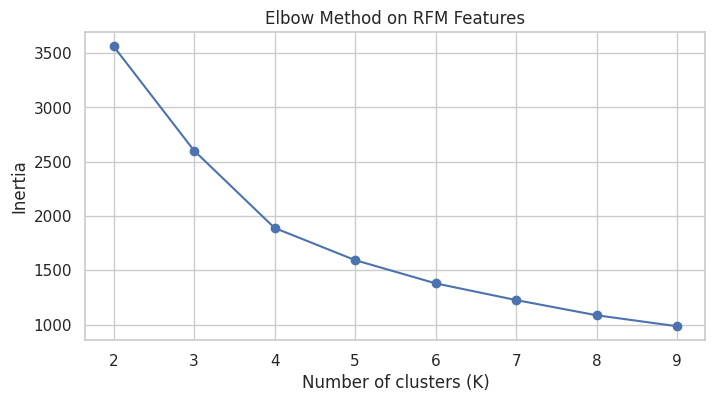

In [ ]:
# Step 5: Elbow Method
from sklearn.cluster import KMeans

K_range = range(2, 10)
inertia = []

for k in K_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(K_range), inertia, marker='o')
plt.title('Elbow Method on RFM Features')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.xticks(list(K_range))
plt.show()


K = 2: Silhouette Score = 0.4192
K = 3: Silhouette Score = 0.3784
K = 4: Silhouette Score = 0.3779
K = 5: Silhouette Score = 0.3700
K = 6: Silhouette Score = 0.3541
K = 7: Silhouette Score = 0.3356
K = 8: Silhouette Score = 0.3423
K = 9: Silhouette Score = 0.3395

Selected K based on the highest silhouette score: 2


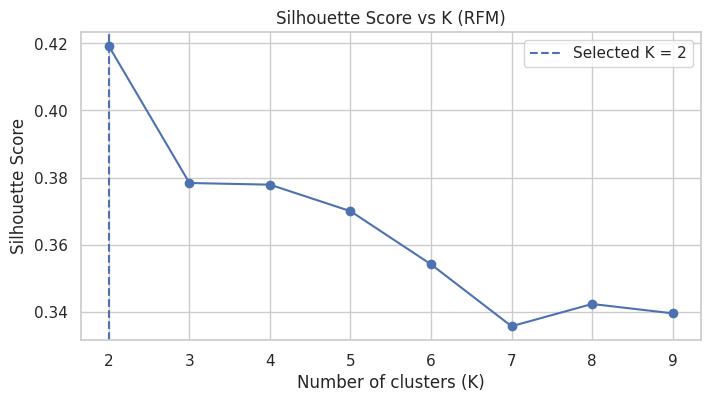

In [ ]:
# Step 6: Compare silhouette scores and select the best K
from sklearn.metrics import silhouette_score

silhouette_scores = []
for k in K_range:
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"K = {k}: Silhouette Score = {score:.4f}")

best_k = list(K_range)[int(np.argmax(silhouette_scores))]
print(f"\nSelected K based on the highest silhouette score: {best_k}")

plt.figure(figsize=(8, 4))
plt.plot(list(K_range), silhouette_scores, marker='o')
plt.axvline(best_k, linestyle='--', label=f'Selected K = {best_k}')
plt.title('Silhouette Score vs K (RFM)')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(K_range))
plt.legend()
plt.show()


K-Means cluster counts:


,Customers
KMeans_Cluster,
0,1184
1,1051


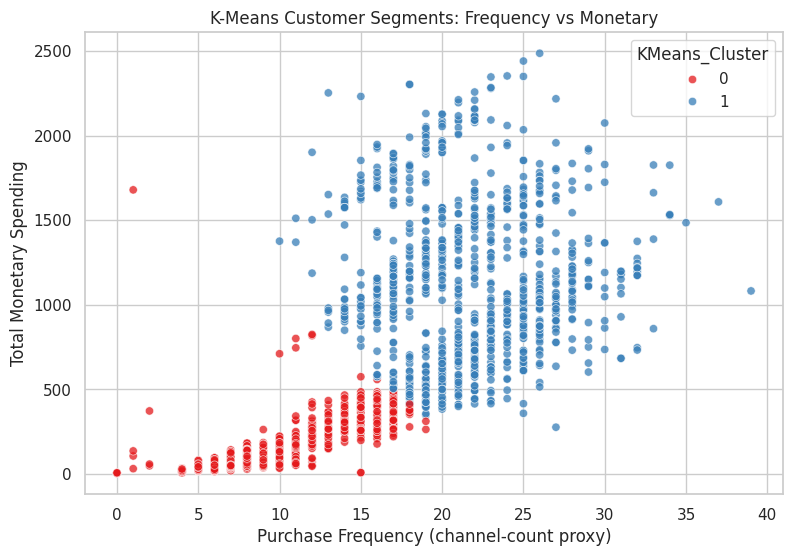

In [ ]:
# Step 7: Fit final K-Means model
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
rfm['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means cluster counts:")
display(rfm['KMeans_Cluster'].value_counts().sort_index().to_frame('Customers'))

plt.figure(figsize=(9, 6))
sns.scatterplot(data=rfm, x='Frequency', y='Monetary',
                hue='KMeans_Cluster', palette='Set1', alpha=0.75)
plt.title('K-Means Customer Segments: Frequency vs Monetary')
plt.xlabel('Purchase Frequency (channel-count proxy)')
plt.ylabel('Total Monetary Spending')
plt.show()


DBSCAN cluster counts (-1 = noise):


,Customers
DBSCAN_Cluster,
-1,4
0,2231


Number of DBSCAN clusters (excluding noise): 1
Noise points: 0.18%


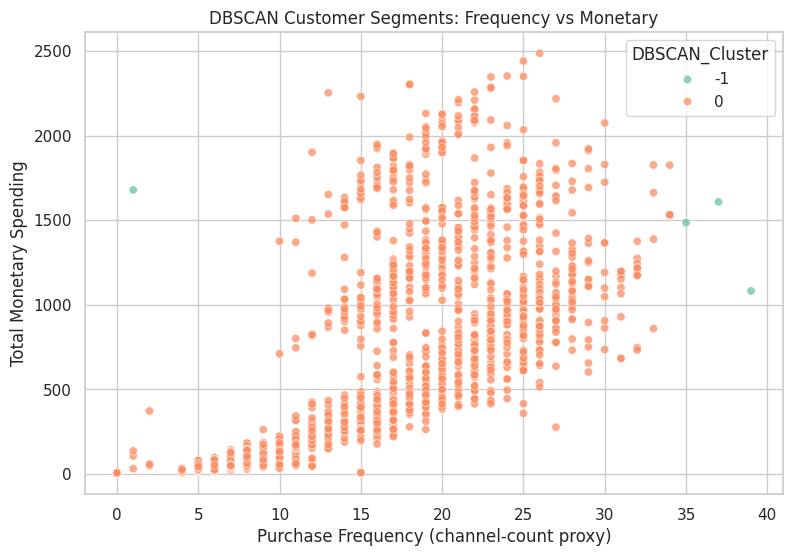

In [ ]:
# Step 8: Apply DBSCAN to scaled RFM data
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.8, min_samples=8)
rfm['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

dbscan_counts = rfm['DBSCAN_Cluster'].value_counts().sort_index()
n_dbscan_clusters = len(set(rfm['DBSCAN_Cluster']) - {-1})
noise_pct = (rfm['DBSCAN_Cluster'].eq(-1).mean()) * 100

print("DBSCAN cluster counts (-1 = noise):")
display(dbscan_counts.to_frame('Customers'))
print(f"Number of DBSCAN clusters (excluding noise): {n_dbscan_clusters}")
print(f"Noise points: {noise_pct:.2f}%")

plt.figure(figsize=(9, 6))
sns.scatterplot(data=rfm, x='Frequency', y='Monetary',
                hue='DBSCAN_Cluster', palette='Set2', alpha=0.75)
plt.title('DBSCAN Customer Segments: Frequency vs Monetary')
plt.xlabel('Purchase Frequency (channel-count proxy)')
plt.ylabel('Total Monetary Spending')
plt.show()


PCA explained variance by first 2 components: 91.86%


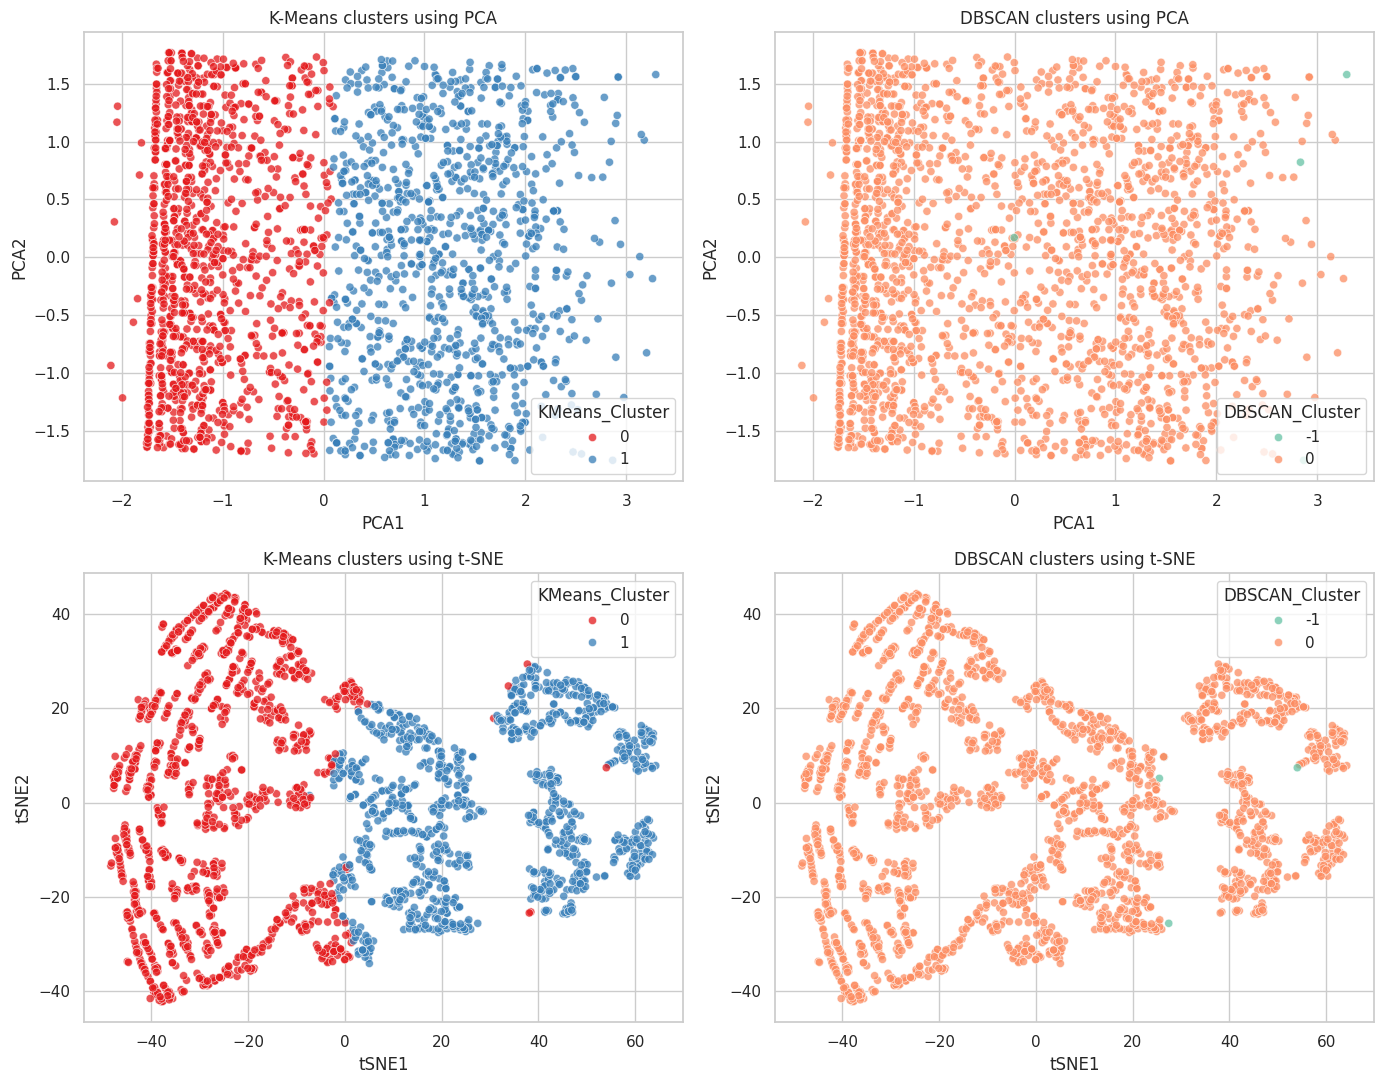

In [ ]:
# Step 9: PCA and t-SNE visualizations
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(X_scaled)
rfm['PCA1'], rfm['PCA2'] = pca_result[:, 0], pca_result[:, 1]

# t-SNE perplexity must be lower than the number of samples
perplexity = min(30, max(5, (len(rfm) - 1) // 3))
tsne = TSNE(n_components=2, perplexity=perplexity,
            random_state=42, init='pca', learning_rate='auto')
tsne_result = tsne.fit_transform(X_scaled)
rfm['tSNE1'], rfm['tSNE2'] = tsne_result[:, 0], tsne_result[:, 1]

print(f"PCA explained variance by first 2 components: {pca.explained_variance_ratio_.sum():.2%}")

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
sns.scatterplot(data=rfm, x='PCA1', y='PCA2', hue='KMeans_Cluster',
                palette='Set1', s=35, alpha=0.75, ax=axes[0, 0])
axes[0, 0].set_title('K-Means clusters using PCA')

sns.scatterplot(data=rfm, x='PCA1', y='PCA2', hue='DBSCAN_Cluster',
                palette='Set2', s=35, alpha=0.75, ax=axes[0, 1])
axes[0, 1].set_title('DBSCAN clusters using PCA')

sns.scatterplot(data=rfm, x='tSNE1', y='tSNE2', hue='KMeans_Cluster',
                palette='Set1', s=35, alpha=0.75, ax=axes[1, 0])
axes[1, 0].set_title('K-Means clusters using t-SNE')

sns.scatterplot(data=rfm, x='tSNE1', y='tSNE2', hue='DBSCAN_Cluster',
                palette='Set2', s=35, alpha=0.75, ax=axes[1, 1])
axes[1, 1].set_title('DBSCAN clusters using t-SNE')

plt.tight_layout()
plt.show()


In [ ]:
# Step 10: Profile K-Means clusters using original RFM values
rfm_profile = rfm.groupby('KMeans_Cluster')[rfm_features].agg(['mean', 'median', 'count'])
display(rfm_profile.round(2))

# Compact mean profile for interpretation
profile = rfm.groupby('KMeans_Cluster')[rfm_features].mean()
display(profile.round(2))

# Rank clusters relative to one another:
# lower Recency is better; higher Frequency and Monetary are better.
cluster_rank = pd.DataFrame(index=profile.index)
cluster_rank['Recency_rank'] = profile['Recency'].rank(ascending=True, pct=True)
cluster_rank['Frequency_rank'] = profile['Frequency'].rank(ascending=True, pct=True)
cluster_rank['Monetary_rank'] = profile['Monetary'].rank(ascending=True, pct=True)

personas = []
for cluster_id, row in profile.iterrows():
    recency_rank = cluster_rank.loc[cluster_id, 'Recency_rank']
    frequency_rank = cluster_rank.loc[cluster_id, 'Frequency_rank']
    monetary_rank = cluster_rank.loc[cluster_id, 'Monetary_rank']

    if frequency_rank >= 0.67 and monetary_rank >= 0.67 and recency_rank <= 0.67:
        persona = 'Champions / High-Value Customers'
        action = 'Reward loyalty with VIP benefits, early access, and referral incentives.'
    elif recency_rank >= 0.67 and (frequency_rank <= 0.67 or monetary_rank <= 0.67):
        persona = 'At-Risk / Lapsing Customers'
        action = 'Run win-back campaigns with personalized reminders and a time-limited offer.'
    elif recency_rank <= 0.67 and frequency_rank >= 0.67:
        persona = 'Loyal Regulars'
        action = 'Use subscriptions, loyalty points, cross-sells, and personalized recommendations.'
    elif frequency_rank <= 0.34 and monetary_rank <= 0.34:
        persona = 'New / Low-Engagement Customers'
        action = 'Use onboarding journeys, best-seller recommendations, and a second-purchase incentive.'
    else:
        persona = 'Potential-Growth Customers'
        action = 'Encourage repeat purchases with relevant bundles and category-based recommendations.'

    personas.append({
        'KMeans_Cluster': cluster_id,
        'Customers': int((rfm['KMeans_Cluster'] == cluster_id).sum()),
        'Avg_Recency_days': round(row['Recency'], 1),
        'Avg_Frequency_proxy': round(row['Frequency'], 1),
        'Avg_Monetary': round(row['Monetary'], 1),
        'Marketing_Persona': persona,
        'Recommended_Action': action
    })

persona_table = pd.DataFrame(personas)
display(persona_table)

# Supplementary demographic and campaign profile, if available
supplementary_cols = [c for c in ['Income', 'Age', 'Children', 'NumWebVisitsMonth'] if c in df.columns]
if supplementary_cols:
    supplementary = df.loc[rfm.index, supplementary_cols].copy()
    supplementary['KMeans_Cluster'] = rfm['KMeans_Cluster']
    print("Supplementary customer characteristics by cluster:")
    display(supplementary.groupby('KMeans_Cluster').mean().round(2))

# Compare K-Means and DBSCAN assignments side by side
print("K-Means vs DBSCAN assignment cross-tabulation:")
display(pd.crosstab(rfm['KMeans_Cluster'], rfm['DBSCAN_Cluster'],
                    margins=True, normalize='index').round(3))


Recency              Frequency              Monetary          \
                  mean median count      mean median count     mean  median   
KMeans_Cluster                                                                
0                48.92   49.0  1184      8.78    8.0  1184   132.21    72.5   
1                49.38   51.0  1051     21.65   21.0  1051  1131.71  1082.0   

                      
               count  
KMeans_Cluster        
0               1184  
1               1051

,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,48.92,8.78,132.21
1,49.38,21.65,1131.71


,KMeans_Cluster,Customers,Avg_Recency_days,Avg_Frequency_proxy,Avg_Monetary,Marketing_Persona,Recommended_Action
0,0,1184,48.9,8.8,132.2,Potential-Growth Customers,Encourage repeat purchases with relevant bundl...
1,1,1051,49.4,21.6,1131.7,Potential-Growth Customers,Encourage repeat purchases with relevant bundl...


Supplementary customer characteristics by cluster:


,Income,NumWebVisitsMonth
KMeans_Cluster,,
0,37669.04,6.30
1,68487.84,4.22


K-Means vs DBSCAN assignment cross-tabulation:


DBSCAN_Cluster,-1,0
KMeans_Cluster,,
0,0.001,0.999
1,0.003,0.997
All,0.002,0.998
